In [21]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, measure, color
from skimage.color import rgb2gray

In [4]:
def mostrar(imagens,titulos,cmap='gray',tamanho=4):
  n = len(imagens)
  plt.figure(figsize=(tamanho*n,tamanho))

  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(imagens[i],cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()


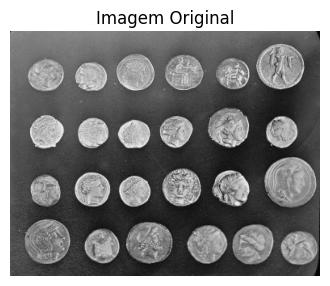

In [17]:
img1 = data.coins()

mostrar([img1],['Imagem Original'])

In [18]:
limiar1 = filters.threshold_otsu(img1)
semantica1 = img1 > limiar1

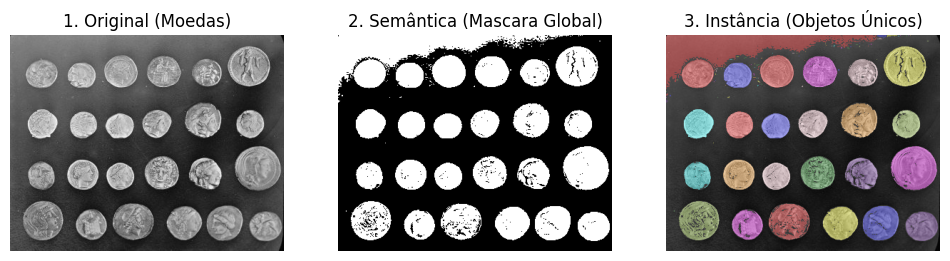

In [ ]:
rotulos_instancia1 = measure.label(semantica1)
instancia1_colorida = color.label2rgb(rotulos_instancia1, image=img1, bg_label=0)

mostrar([img1, semantica1, instancia1_colorida], 
        ['1. Original (Moedas)', '2. Semântica (Mascara Global)', '3. Instância (Objetos Únicos)'])

nessa imagem, os objetos estão bem separados uns dos outros e contrastam fortemente com o fundo escuro, o que permitiu que a segmentação por instância identificasse e isolasse cada moeda com sucesso, atribuindo a eles cores distintas

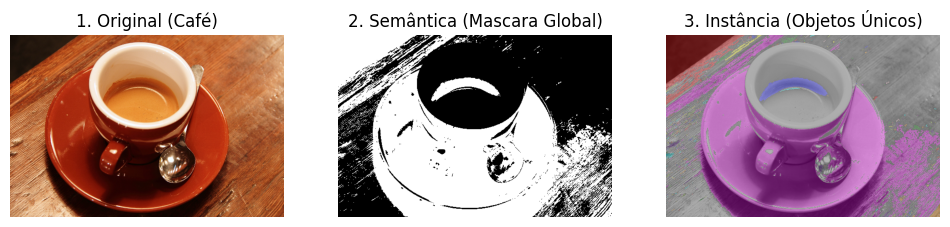

In [ ]:
img2_rgb = data.coffee()
# convertendo para tons de cinza para aplicar a limiarização
img2 = rgb2gray(img2_rgb)

limiar2 = filters.threshold_otsu(img2)
# pegando os pixels mais escuros (grãos e xícara)
semantica2 = img2 < limiar2

rotulos_instancia2 = measure.label(semantica2)
instancia2_colorida = color.label2rgb(rotulos_instancia2, image=img2_rgb, bg_label=0)

mostrar([img2_rgb, semantica2, instancia2_colorida], 
        ['1. Original (Café)', '2. Semântica (Mascara Global)', '3. Instância (Objetos Únicos)'])

nessa, a iluminação, os reflexos e a sobreposição de elementos (como o pires, a xícara e o café) confundiram a separação. a segmentação aglomerou partes conectadas da xícara, do pires e do fundo em grandes blocos únicos, falhando em isolar os objetos individuais corretamente.